In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [27]:
import pandas as pd
from scipy.sparse import load_npz


#utility_matrix_real = load_npz("/content/drive/MyDrive/SML/processed_data/utility_matrix_real_binary.npz")
x = pd.read_csv('/content/drive/MyDrive/SML/processed_data/interactions_real_long.csv')
x

,customer_id_anon,work_id,distinct_orders,units,total_spend,first_purchase,last_purchase,binary_utility,repeat_purchase_utility,interaction_source,simulation_rule,simulation_seed,simulation_score
0,customer_000001,work_isbn13_9786071608062,1,1.0,19990.0,2019-10-17 15:21:16+00:00,2019-10-17 15:21:16+00:00,1.0,1.0,observed,NaN,NaN,NaN
1,customer_000002,product_4358886621265,1,1.0,3500.0,2020-01-09 19:06:21+00:00,2020-01-09 19:06:21+00:00,1.0,1.0,observed,NaN,NaN,NaN
2,customer_000002,work_isbn13_9786071600677,1,1.0,12720.0,2020-01-23 15:59:36+00:00,2020-01-23 15:59:36+00:00,1.0,1.0,observed,NaN,NaN,NaN
3,customer_000002,work_isbn13_9786071657114,1,1.0,9520.0,2020-01-23 16:03:53+00:00,2020-01-23 16:03:53+00:00,1.0,1.0,observed,NaN,NaN,NaN
4,customer_000003,work_isbn13_9786071635372,1,1.0,17430.0,2020-04-20 17:33:17+00:00,2020-04-20 17:33:17+00:00,1.0,1.0,observed,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
136827,customer_023602,work_isbn13_9789564183015,1,1.0,7920.0,2025-12-30 21:02:20+00:00,2025-12-30 21:02:20+00:00,1.0,1.0,observed,NaN,NaN,NaN
136828,customer_023603,work_isbn13_9786071683106,1,1.0,7120.0,2025-12-30 22:52:08+00:00,2025-12-30 22:52:08+00:00,1.0,1.0,observed,NaN,NaN,NaN
136829,customer_023603,work_isbn13_9789681680794,1,1.0,12720.0,2025-12-30 22:52:08+00:00,2025-12-30 22:52:08+00:00,1.0,1.0,observed,NaN,NaN,NaN
136830,customer_023604,work_isbn13_9789877195507,1,1.0,9030.0,2025-12-30 23:29:47+00:00,2025-12-30 23:29:47+00:00,1.0,1.0,observed,NaN,NaN,NaN


In [28]:
x.groupby('customer_id_anon').size().value_counts()

,count
1,8293
2,3434
3,2448
4,1628
5,1197
...,...
158,1
124,1
169,1
102,1


[]

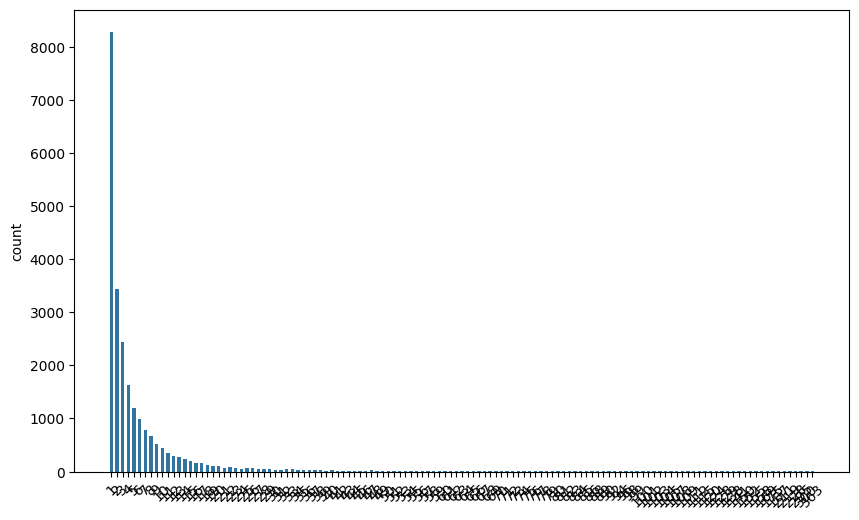

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
freq = x.groupby('customer_id_anon').size().value_counts().sort_values(ascending = True)

plt.figure(figsize = (10,6))
sns.barplot(freq, width = 0.6)
plt.xticks(rotation = 45)
plt.plot()

In [30]:
"""
Costruzione di train/test per il progetto di double descent nel
collaborative filtering one-class (dataset utente-libro, solo acquisti).

Procedura:
  1. Filtro: si tengono solo gli utenti con almeno MIN_INTERACTIONS interazioni
     (rimuove chi ha 1 o 2 transazioni, poco informativi e problematici per lo split).
  2. Split leave-one-out CASUALE: per ogni utente un acquisto scelto a caso
     (seed fisso) va nel test, tutto il resto nel train.
  3. Pulizia cold-item: si rimuovono dal test gli acquisti il cui libro non compare
     mai nel train (la matrix factorization non puo assegnargli un punteggio).
  4. Controlli di integrita (no leakage) e salvataggio.

Uso:
    python build_train_test.py
"""

import pandas as pd

# ----------------------------------------------------------------------
# Parametri
# ----------------------------------------------------------------------
INPUT_PATH  = "/content/drive/MyDrive/SML/processed_data/interactions_real_long.csv"
TRAIN_PATH  = "train.csv"
TEST_PATH   = "test.csv"
MIN_INTERACTIONS =  25  # tieni utenti con >= 3 interazioni (rimuove 1 e 2 transazioni)
SEED = 20060709        # seed per lo split casuale (riproducibilita)

# Colonne originali da conservare nell'output
KEEP_COLS = ["customer_id_anon", "work_id", "distinct_orders", "units",
             "total_spend", "first_purchase", "last_purchase", "binary_utility"]


def main():
    # ------------------------------------------------------------------
    # 0. Caricamento
    # ------------------------------------------------------------------
    df = pd.read_csv(INPUT_PATH)

    n_users0, n_items0, n_int0 = (df["customer_id_anon"].nunique(),
                                  df["work_id"].nunique(), len(df))

    # ------------------------------------------------------------------
    # 1. Filtro sugli utenti poco attivi
    #    (transform('size') conta le righe per utente senza collassare il df)
    # ------------------------------------------------------------------
    per_user = df.groupby("customer_id_anon")["work_id"].transform("size")
    kept = df[per_user >= MIN_INTERACTIONS].copy()

    # ------------------------------------------------------------------
    # 2. Split leave-one-out CASUALE
    #    Per ogni utente si estrae a caso una riga (l'acquisto held-out) da
    #    mettere nel test; il resto va nel train. sample(frac=1) mescola in modo
    #    riproducibile con random_state=SEED, poi cumcount==0 prende il primo
    #    di ciascun gruppo (che, essendo mescolato, e' casuale).
    # ------------------------------------------------------------------
    kept = kept.sample(frac=1, random_state=SEED).reset_index(drop=True)
    pick = kept.groupby("customer_id_anon").cumcount()
    test  = kept[pick == 0].copy()   # 1 riga casuale per utente
    train = kept[pick != 0].copy()   # tutto il resto

    # ------------------------------------------------------------------
    # 3. Pulizia cold-item: item di test mai visti in train
    # ------------------------------------------------------------------
    train_items = set(train["work_id"].unique())
    cold = ~test["work_id"].isin(train_items)
    test = test[~cold].copy()

    # ------------------------------------------------------------------
    # 4. Controlli di integrita
    # ------------------------------------------------------------------
    # nessuna coppia (utente, libro) duplicata
    assert train.duplicated(["customer_id_anon", "work_id"]).sum() == 0
    assert test.duplicated(["customer_id_anon", "work_id"]).sum() == 0
    # nessun leakage: nessuna coppia (utente, libro) condivisa tra train e test
    leak = test.merge(train[["customer_id_anon", "work_id"]],
                      on=["customer_id_anon", "work_id"], how="inner")
    assert len(leak) == 0, "leakage tra train e test!"
    # ogni utente valutato ha >= MIN_INTERACTIONS-1 interazioni in train
    assert train.groupby("customer_id_anon").size().min() >= MIN_INTERACTIONS - 1

    # ------------------------------------------------------------------
    # 5. Salvataggio
    # ------------------------------------------------------------------
    train_out = train[KEEP_COLS].sort_values(["customer_id_anon", "last_purchase"])
    test_out  = test[KEEP_COLS].sort_values(["customer_id_anon", "last_purchase"])
    train_out.to_csv(TRAIN_PATH, index=False)
    test_out.to_csv(TEST_PATH, index=False)

    # ------------------------------------------------------------------
    # Report
    # ------------------------------------------------------------------
    n, m, omega = (train_out["customer_id_anon"].nunique(),
                   train_out["work_id"].nunique(), len(train_out))
    print(f"Input : {n_users0} utenti, {n_items0} libri, {n_int0} interazioni")
    print(f"Filtro>= {MIN_INTERACTIONS}: {kept['customer_id_anon'].nunique()} utenti, "
          f"{len(kept)} interazioni")
    print(f"Cold-item rimossi dal test: {int(cold.sum())}")
    print(f"train.csv: {len(train_out)} righe, {n} utenti, {m} libri")
    print(f"test.csv : {len(test_out)} righe, {test_out['customer_id_anon'].nunique()} utenti, "
          f"{test_out['work_id'].nunique()} libri")
    print(f"Soglia interpolazione (soli positivi): k* ~ {omega/(n+m):.1f}  "
          f"[con negative sampling a rapporto r: k* ~ {omega/(n+m):.1f} * (1+r)]")


if __name__ == "__main__":
    main()

Input : 23605 utenti, 4405 libri, 136832 interazioni
Filtro>= 25: 916 utenti, 40601 interazioni
Cold-item rimossi dal test: 17
train.csv: 39685 righe, 916 utenti, 3667 libri
test.csv : 899 righe, 899 utenti, 624 libri
Soglia interpolazione (soli positivi): k* ~ 8.7  [con negative sampling a rapporto r: k* ~ 8.7 * (1+r)]


NMF con negative sample

In [32]:
train = pd.read_csv("train.csv")
test  = pd.read_csv("test.csv")

In [33]:
import numpy as np
import scipy.sparse as sp
from collections import defaultdict
# --- indici interi contigui (fittati sul TRAIN) ---
users = train["customer_id_anon"].unique()
items = train["work_id"].unique()
u2i = {u: k for k, u in enumerate(users)} # trasforma gli id in integer
w2i = {w: k for k, w in enumerate(items)}
n_users, n_items = len(users), len(items)
all_items = np.arange(n_items)

# --- interazioni positive di train come array di indici ---
tr_u = train["customer_id_anon"].map(u2i).to_numpy()
tr_i = train["work_id"].map(w2i).to_numpy()

# --- item di train per ciascun utente (per masking e negative sampling) ---
_tmp = defaultdict(list)
for u, i in zip(tr_u, tr_i):
    _tmp[u].append(i)
user_pos_arr = [np.array(_tmp.get(u, []), dtype=np.int64) for u in range(n_users)]

# --- dizionario test: utente -> unico item held-out ---
# (tutti gli utenti/item di test sono nel train per costruzione; filtro per sicurezza)
test_dict = {}
for u_raw, w_raw in zip(test["customer_id_anon"], test["work_id"]):
    if u_raw in u2i and w_raw in w2i:
        test_dict[u2i[u_raw]] = w2i[w_raw]

print(f"utenti={n_users}, libri={n_items}, positivi train={len(tr_u)}, utenti test={len(test_dict)}")

utenti=916, libri=3667, positivi train=39685, utenti test=899


In [34]:
# Campiono i negativi UNA volta e li riuso per tutto lo sweep di k,
# così Omega resta fisso e i k sono confrontabili.
# Per ogni utente: neg_ratio * (#positivi) negativi, presi tra i libri NON acquistati.

NEG_RATIO = 4
SEED_NEG  = 0

def build_omega(neg_ratio, seed):
    rng = np.random.default_rng(seed)
    neg_rows, neg_cols = [], []
    for u in range(n_users):
        pos = user_pos_arr[u]
        if len(pos) == 0:
            continue
        pool = np.setdiff1d(all_items, pos, assume_unique=False)  # libri non acquistati
        n_neg = min(neg_ratio * len(pos), len(pool))
        neg = rng.choice(pool, size=n_neg, replace=False) # estrae un elemnto casuale
        neg_rows.append(np.full(n_neg, u, dtype=np.int64))
        neg_cols.append(neg)
    neg_rows = np.concatenate(neg_rows)
    neg_cols = np.concatenate(neg_cols)

    rows = np.concatenate([tr_u, neg_rows]).astype(np.int32)
    cols = np.concatenate([tr_i, neg_cols]).astype(np.int32)
    vals = np.concatenate([np.ones(len(tr_u), np.float32),
                           np.zeros(len(neg_rows), np.float32)])   # 1 = acquisto, 0 = negativo
    return rows, cols, vals

OMEGA = build_omega(NEG_RATIO, SEED_NEG)
print(f"|Omega| = {len(OMEGA[0])}  (positivi={len(tr_u)}, negativi={len(OMEGA[0])-len(tr_u)})")
print(f"soglia interpolazione attesa k* ~ {len(OMEGA[0])/(n_users+n_items):.1f}")

|Omega| = 198425  (positivi=39685, negativi=158740)
soglia interpolazione attesa k* ~ 43.3


In [35]:
# Obiettivo minimizzato (solo sulle celle di Omega, come nel paper):
#   sum_{(u,i) in Omega} (X_ui - P_u . Q_i)^2 + reg*||P||^2 + reg*||Q||^2,   con P,Q >= 0
# P = fattori utente (n_users x k) = W ;  Q = fattori item (n_items x k) = H^T
# Aggiornamenti moltiplicativi mascherati (equivalenti alle eq. 3-4 del paper):
#   P <- P * (A@Q) / (Ppred@Q + reg*P)
#   Q <- Q * (A^T@P) / (Ppred^T@P + reg*Q)
# dove A = target sulle celle di Omega (1 sui positivi, 0 sui negativi)
#       Ppred = predizioni valutate SOLO sulle celle di Omega

# CON 'MASCHERATA' SI INTENDE CALCOLARE L'ERRORE E AGGIORNARE I FATTORI SOLO SULLE CELLE CHE
# APPARTENGONO A OMEGA, IGNORANDO TUTTE LE ALTRE. OMEGA è L'INSIEME DELLE CELLE CHE HO DECISO
# DI CONSIDERARE: ACQUISTI + NEGATIVE SAMPLES

def _predict_pairs(P, Q, rows, cols, chunk=200_000):
    """Predizione P_u . Q_i solo sulle coppie (rows,cols), a blocchi per la memoria."""
    out = np.empty(len(rows), dtype=np.float32)
    for s in range(0, len(rows), chunk):
        e = s + chunk
        out[s:e] = np.sum(P[rows[s:e]] * Q[cols[s:e]], axis=1)
    return out

def fit_nmf(k, omega, n_epochs=100, reg=0.06, seed=0, chunk=200_000, verbose=False):
    rng = np.random.default_rng(seed)
    P = rng.uniform(0.0, 1.0, size=(n_users, k)).astype(np.float32)   # init uniforme [0,1] come nel paper
    Q = rng.uniform(0.0, 1.0, size=(n_items, k)).astype(np.float32)
    eps = np.float32(1e-9)

    rows, cols, vals = omega
    A  = sp.csr_matrix((vals, (rows, cols)), shape=(n_users, n_items), dtype=np.float32)  # target su Omega
    AT = A.T.tocsr()

    for ep in range(n_epochs):
        # --- update fattori utente P ---
        pred = _predict_pairs(P, Q, rows, cols, chunk)
        Pp   = sp.csr_matrix((pred, (rows, cols)), shape=(n_users, n_items), dtype=np.float32)
        P *= (A @ Q) / (Pp @ Q + reg * P + eps)

        # --- update fattori item Q (ricalcolo le predizioni con P aggiornato) ---
        pred = _predict_pairs(P, Q, rows, cols, chunk)
        Pp   = sp.csr_matrix((pred, (rows, cols)), shape=(n_users, n_items), dtype=np.float32)
        Q *= (AT @ P) / (Pp.T.tocsr() @ P + reg * Q + eps)

        if verbose and (ep + 1) % 20 == 0:
            print(f"  epoch {ep+1}/{n_epochs}")
    return P, Q

In [36]:
# --- train error: RMSE sulle celle di Omega (le stesse su cui si addestra) ---
def rmse_train(P, Q, omega):
    rows, cols, vals = omega
    s = _predict_pairs(P, Q, rows, cols)             # predizioni sulle celle di Omega
    return float(np.sqrt(np.mean((vals - s) ** 2)))  # vals = 1 sui positivi, 0 sui negativi

In [37]:
# --- eval pointwise a proporzione configurabile (1 positivo : n_neg negativi per utente) ---
def build_eval_pointwise(n_neg=100, seed=1):
    rng = np.random.default_rng(seed)
    eu, ei, er = [], [], []
    for u, ho in test_dict.items():
        eu.append(u); ei.append(ho); er.append(1.0)
        pool = np.setdiff1d(all_items, np.append(user_pos_arr[u], ho))
        neg  = rng.choice(pool, size=min(n_neg, len(pool)), replace=False)
        eu.extend([u] * len(neg)); ei.extend(neg.tolist()); er.extend([0.0] * len(neg))
    return np.array(eu), np.array(ei), np.array(er, dtype=np.float32)

# due metri diversi, calcolati una volta sola e riusati per tutto lo sweep:
EVAL_PW_100 = build_eval_pointwise(n_neg=100, seed=1)   # sbilanciato, come prima
EVAL_PW_4   = build_eval_pointwise(n_neg=4,   seed=1)   # bilanciato 1:4

def rmse_pointwise(P, Q, eval_pw):
    eu, ei, er = eval_pw
    s = _predict_pairs(P, Q, eu, ei)                 # punteggi grezzi, non clippati
    return float(np.sqrt(np.mean((er - s) ** 2)))    # RMSE = sqrt(Brier) su target 0/1

# --- ranking sull'intero catalogo, con masking degli item gia' nel train ---
def ranking_metrics(P, Q, Ks=(5, 10, 20)):
    test_users = np.fromiter(test_dict.keys(), dtype=np.int64)
    ho_items   = np.fromiter((test_dict[u] for u in test_users), dtype=np.int64)

    S = (P[test_users] @ Q.T).astype(np.float32)   # (n_test x n_items) punteggi grezzi

    # maschero i positivi di train di questi utenti (train masking)
    user_to_row = -np.ones(n_users, dtype=np.int64)
    user_to_row[test_users] = np.arange(len(test_users))
    rr = user_to_row[tr_u]
    keep = rr >= 0
    S[rr[keep], tr_i[keep]] = -np.inf

    ho_scores = S[np.arange(len(test_users)), ho_items]     # punteggio del libro held-out
    ranks = (S > ho_scores[:, None]).sum(axis=1) + 1        # posizione in classifica (1 = top)

    out = {}
    for K in Ks:
        hit = ranks <= K
        out[f"Recall@{K}"] = float(hit.mean())                       # = HitRate@K (1 positivo/utente)
        out[f"NDCG@{K}"]   = float((hit / np.log2(ranks + 1)).mean())
    return out

In [38]:
import time

# griglia estesa oltre 1024 per catturare l'assestamento della seconda discesa
K_GRID = [1, 2, 4, 8, 16, 24, 32, 48, 64, 96, 128, 192, 256, 384, 512, 768,
          1024, 1536, 2048, 3072]

# epoche adattive: meno epoche ai k grandi (il minimo di test error si raggiunge prima,
# e il costo per epoca cresce ~linearmente in k). Sotto la soglia restiamo a 100.
def n_epochs_for(k):
    if k <= 512:   return 100
    if k <= 2048:  return 60
    if k <= 8192:  return 40
    return 30

rows_res = []
for k in K_GRID:
    t0 = time.time()
    ep = n_epochs_for(k)
    P, Q = fit_nmf(k=k, omega=OMEGA, n_epochs=ep, reg=0.06, seed=0)
    rec = {
        "k": k,
        "epochs": ep,
        "rmse_train":    rmse_train(P, Q, OMEGA),          # NUOVO: errore di training
        "rmse_test_100": rmse_pointwise(P, Q, EVAL_PW_100),# test, eval sbilanciato 1:100
        "rmse_test_4":   rmse_pointwise(P, Q, EVAL_PW_4),  # NUOVO: test, eval bilanciato 1:4
        **ranking_metrics(P, Q),
    }
    rec["sec"] = round(time.time() - t0, 1)
    rows_res.append(rec)
    print(rec)

results = pd.DataFrame(rows_res)
results.to_csv("nmf_sweep_results_2.csv", index=False)
results

{'k': 1, 'epochs': 100, 'rmse_train': 0.3519476056098938, 'rmse_test_100': 0.22673113644123077, 'rmse_test_4': 0.3486623466014862, 'Recall@5': 0.027808676307007785, 'NDCG@5': 0.018131004370408675, 'Recall@10': 0.047830923248053395, 'NDCG@10': 0.024722307248802373, 'Recall@20': 0.07563959955506118, 'NDCG@20': 0.031793087838845165, 'sec': 2.7}
{'k': 2, 'epochs': 100, 'rmse_train': 0.3203772008419037, 'rmse_test_100': 0.22842274606227875, 'rmse_test_4': 0.322639524936676, 'Recall@5': 0.04004449388209121, 'NDCG@5': 0.026490774765765165, 'Recall@10': 0.07119021134593993, 'NDCG@10': 0.036481316483800284, 'Recall@20': 0.11568409343715239, 'NDCG@20': 0.04740182114991931, 'sec': 5.4}
{'k': 4, 'epochs': 100, 'rmse_train': 0.30052968859672546, 'rmse_test_100': 0.23108866810798645, 'rmse_test_4': 0.3152366280555725, 'Recall@5': 0.04338153503893215, 'NDCG@5': 0.02618232786064122, 'Recall@10': 0.08008898776418243, 'NDCG@10': 0.03772466014164095, 'Recall@20': 0.13793103448275862, 'NDCG@20': 0.0521630

,k,epochs,rmse_train,rmse_test_100,rmse_test_4,Recall@5,NDCG@5,Recall@10,NDCG@10,Recall@20,NDCG@20,sec
0,1,100,0.351948,0.226731,0.348662,0.027809,0.018131,0.047831,0.024722,0.075640,0.031793,2.7
1,2,100,0.320377,0.228423,0.322640,0.040044,0.026491,0.071190,0.036481,0.115684,0.047402,5.4
2,4,100,0.300530,0.231089,0.315237,0.043382,0.026182,0.080089,0.037725,0.137931,0.052163,4.4
3,8,100,0.279367,0.263808,0.328394,0.034483,0.019927,0.063404,0.029236,0.131257,0.046164,6.2
4,16,100,0.250652,0.354481,0.429918,0.014461,0.007566,0.030033,0.012640,0.081201,0.025598,6.9
5,24,100,0.224255,0.412534,0.479046,0.010011,0.005601,0.020022,0.008581,0.054505,0.017203,9.6
6,32,100,0.202345,0.471662,0.533110,0.005562,0.003328,0.016685,0.006786,0.045606,0.013933,9.7
7,48,100,0.165266,0.480556,0.543333,0.003337,0.002927,0.010011,0.004968,0.023359,0.008290,15.2
8,64,100,0.136813,0.498696,0.551733,0.010011,0.005504,0.020022,0.008765,0.041157,0.014079,18.9
9,96,100,0.100732,0.425393,0.513338,0.005562,0.002869,0.014461,0.005687,0.025584,0.008354,28.4


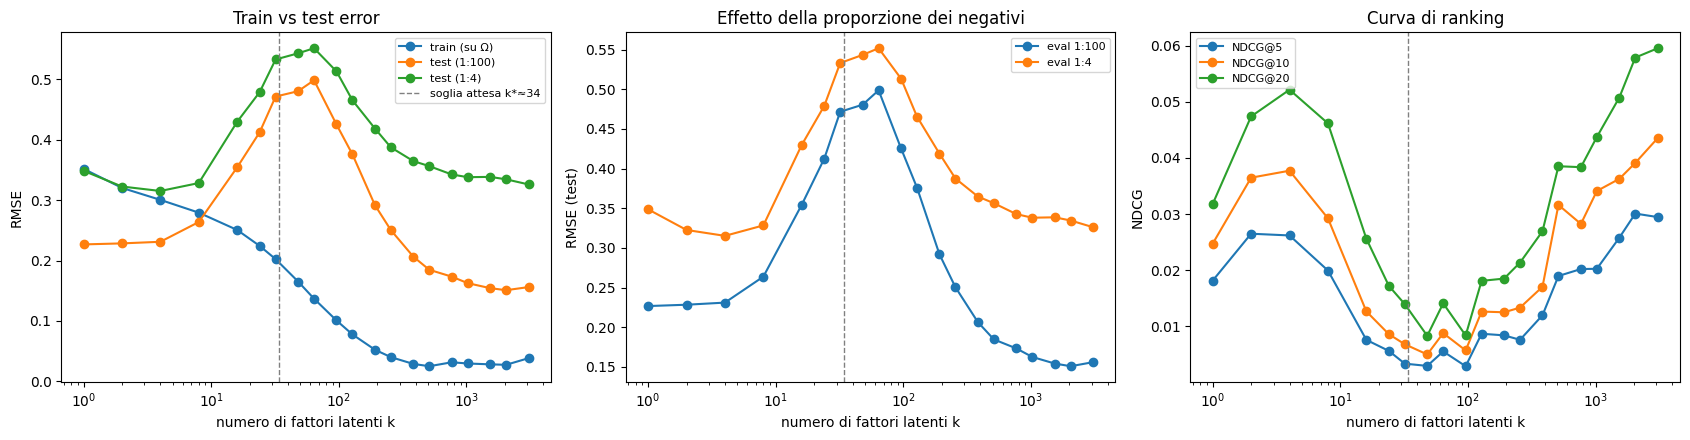

In [39]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# (1) train vs test error: la firma dell'interpolazione
ax[0].plot(results["k"], results["rmse_train"],    marker="o", label="train (su Ω)")
ax[0].plot(results["k"], results["rmse_test_100"], marker="o", label="test (1:100)")
ax[0].plot(results["k"], results["rmse_test_4"],   marker="o", label="test (1:4)")
ax[0].axvline(34, ls="--", c="gray", lw=1, label="soglia attesa k*≈34")
ax[0].set_xscale("log"); ax[0].set_xlabel("numero di fattori latenti k")
ax[0].set_ylabel("RMSE"); ax[0].set_title("Train vs test error"); ax[0].legend(fontsize=8)

# (2) confronto dei due eval pointwise di test
ax[1].plot(results["k"], results["rmse_test_100"], marker="o", label="eval 1:100")
ax[1].plot(results["k"], results["rmse_test_4"],   marker="o", label="eval 1:4")
ax[1].axvline(34, ls="--", c="gray", lw=1)
ax[1].set_xscale("log"); ax[1].set_xlabel("numero di fattori latenti k")
ax[1].set_ylabel("RMSE (test)"); ax[1].set_title("Effetto della proporzione dei negativi"); ax[1].legend(fontsize=8)

# (3) ranking
for K in (5, 10, 20):
    ax[2].plot(results["k"], results[f"NDCG@{K}"], marker="o", label=f"NDCG@{K}")
ax[2].axvline(34, ls="--", c="gray", lw=1)
ax[2].set_xscale("log"); ax[2].set_xlabel("numero di fattori latenti k")
ax[2].set_ylabel("NDCG"); ax[2].set_title("Curva di ranking"); ax[2].legend(fontsize=8)

plt.tight_layout(); plt.show()